# Cookie Cats A/B Test: Hypothesis Testing

**H₀:** moving the gate from level 30 to 40 has no effect on retention.
**H₁:** it changes retention. Significance level **α = 0.05**, two-sided.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

plt.style.use("default")

df = pd.read_csv("../data/cookie_cats.csv")
df = df[df["sum_gamerounds"] < df["sum_gamerounds"].max()]   # remove the outlier from Step 1
df.shape

(90188, 5)

In [2]:
is_40 = (df["version"] == "gate_40").values
ret7 = df["retention_7"].values.astype(int)

observed_diff = ret7[is_40].mean() - ret7[~is_40].mean()
print(f"7-day retention: gate_40 - gate_30 = {observed_diff:.4%}")

7-day retention: gate_40 - gate_30 = -0.8183%


In [3]:
rng = np.random.default_rng(42)
shuffled_diffs = []

for _ in range(2000):
    fake_labels = rng.permutation(is_40)
    shuffled_diffs.append(ret7[fake_labels].mean() - ret7[~fake_labels].mean())

shuffled_diffs = np.array(shuffled_diffs)
p_value_perm = (np.abs(shuffled_diffs) >= abs(observed_diff)).mean()

print(f"Typical luck-only difference (std): {shuffled_diffs.std():.4%}")
print(f"Permutation p-value: {p_value_perm:.4f}")

Typical luck-only difference (std): 0.2619%
Permutation p-value: 0.0030


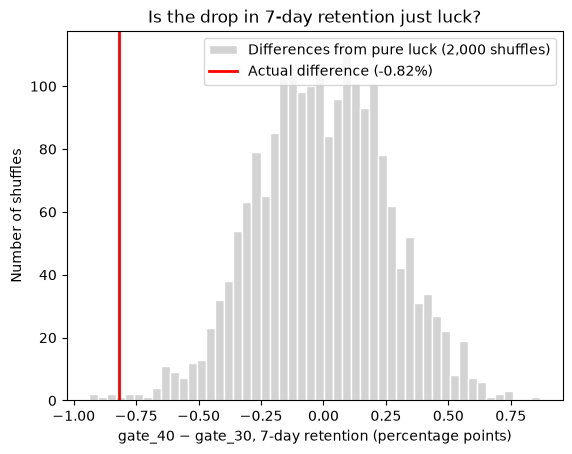

In [4]:
plt.hist(shuffled_diffs * 100, bins=50, color="lightgray", edgecolor="white",
         label="Differences from pure luck (2,000 shuffles)")
plt.axvline(observed_diff * 100, color="red", linewidth=2,
            label=f"Actual difference ({observed_diff:.2%})")
plt.xlabel("gate_40 − gate_30, 7-day retention (percentage points)")
plt.ylabel("Number of shuffles")
plt.title("Is the drop in 7-day retention just luck?")
plt.legend()
plt.savefig("../images/permutation_test_retention7.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
def compare_retention(metric):
    groups = df.groupby("version")[metric].agg(["sum", "count"]).loc[["gate_40", "gate_30"]]
    successes, totals = groups["sum"].values, groups["count"].values
    rates = successes / totals

    z, p = proportions_ztest(successes, totals)
    low, high = confint_proportions_2indep(successes[0], totals[0], successes[1], totals[1],
                                           compare="diff")
    diff = rates[0] - rates[1]
    return {
        "gate_30": round(rates[1] * 100, 2),
        "gate_40": round(rates[0] * 100, 2),
        "diff_pts": round(diff * 100, 2),
        "relative_change_%": round(diff / rates[1] * 100, 1),
        "95%_CI_pts": f"[{low * 100:.2f}, {high * 100:.2f}]",
        "z": round(z, 2),
        "p_value": round(p, 4),
        "significant": p < 0.05,
    }

results = pd.DataFrame({m: compare_retention(m) for m in ["retention_1", "retention_7"]}).T
results

,gate_30,gate_40,diff_pts,relative_change_%,95%_CI_pts,z,p_value,significant
retention_1,44.82,44.23,-0.59,-1.3,"[-1.24, 0.06]",-1.79,0.0739,False
retention_7,19.02,18.2,-0.82,-4.3,"[-1.33, -0.31]",-3.16,0.0016,True


## Results

| Metric | gate_30 | gate_40 | Difference | 95% CI | p-value |
|---|---|---|---|---|---|
| 1-day retention | 44.82% | 44.23% | −0.59 pts | [−1.24, +0.06] | 0.074 (not significant) |
| 7-day retention | 19.02% | 18.20% | **−0.82 pts (−4.3%)** | [−1.33, −0.31] | **0.0016 (significant)** |

- **7-day retention is significantly lower with the gate at level 40.** A permutation test
  (2,000 shuffles, p = 0.003) and a two-proportion z-test (p = 0.0016) agree.
- **1-day retention shows no significant difference.** This makes sense: most players haven't
  reached level 30 by day 1 (median 16 rounds), so both groups have the same early experience.
- **Practical size:** about **818 fewer players still active after a week per 100,000 installs**.
- **Caveat:** the sample ratio mismatch from Step 1 (p = 0.009) slightly reduces confidence.

**Conclusion so far:** keep the gate at **level 30**. Moving it to level 40 hurts week-1 retention.